# 01 梯度下降 Gradient-Descent(GD)

## 1. 算法介绍

通过迭代找目标函数（一般是损失函数）最小值，每一步都沿最陡峭的方向走，走的长度称为步长或学习率。

最小二乘法直接计算最优解，梯度下降从一个初始值开始，一步一步逼近最优解。都可用于线性回归。

## 2. 数学原理



$$ \boxed{ \theta_{t+1} = \theta_t-\alpha\nabla J(\theta_t) } $$

这就是梯度下降的数学核心。

使用均方误差：

$$ J(b_0,b_1) = \frac{1}{2n} \sum_{i=1}^{n} (y_i-b_0-b_1x_i)^2 $$

前面放$ \frac{1}{2} $是为了求导的时候方便。

对 \(b_0\) 求偏导

得到：

$$ \boxed{ \frac{\partial J}{\partial b_0} = -\frac{1}{n} \sum_{i=1}^{n} (y_i-\hat y_i) } $$
对 \(b_1\) 求偏导

得到：

$$ \boxed{ \frac{\partial J}{\partial b_1} = -\frac{1}{n} \sum_{i=1}^{n} x_i(y_i-\hat y_i) } $$

所以：

$$ \boxed{ b_0 \leftarrow b_0+ \frac{\alpha}{n} \sum_{i=1}^{n} (y_i-\hat y_i) } $$

同理：

$$ \boxed{ b_1 \leftarrow b_1+ \frac{\alpha}{n} \sum_{i=1}^{n} x_i(y_i-\hat y_i) } $$

这两个公式就是：

使用梯度下降训练线性回归模型。


## 3. 导入相关库

In [1]:
import numpy as np

## 4. 构造数据

In [2]:
X = np.array([1, 2, 3, 4, 5, 6, 7, 8])
Y = np.array([52, 55, 61, 65, 68, 72, 78, 81])

## 5. 手动实现

In [3]:
b0 = 0
b1 = 0

n = len(X)
learning_rate = 0.01
epochs = 1000

for i in range(epochs):
    Y_hat = b0 + b1 * X
    b0 = b0 + (learning_rate * np.sum(Y - Y_hat))/n
    b1 = b1 + (learning_rate * np.sum(X * (Y - Y_hat)))/n

J = np.sum((Y - b0 - b1 * X)**2)/(2*n)
print(J)

4.147539460963472


## 6. 使用 scikit-learn 库实现

In [4]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

X1 = X.reshape(-1, 1)
model = SGDRegressor()
model.fit(X1, Y);
Y_hat = model.predict(X1)
MSE = mean_squared_error(Y, Y_hat)

print("MSE/2 =", MSE/2)

MSE/2 = 2.5202831436012687


c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


## 7. 可视化

[np.float64(1322.4812636718748), np.float64(813.9592787913575), np.float64(537.3678064828612), np.float64(386.75400837771235), np.float64(304.56817951135616), np.float64(259.5514231589522), np.float64(234.72504616546468), np.float64(220.86683864644945), np.float64(212.96762819889082), np.float64(208.3066100065511), np.float64(205.40593668727166), np.float64(203.46288980950953), np.float64(202.0414562694701), np.float64(200.90480388199904), np.float64(199.92428826079822), np.float64(199.030028690328), np.float64(198.18406275059775), np.float64(197.36576489307475), np.float64(196.56392634539577), np.float64(195.77245320576725), np.float64(194.98802980540535), np.float64(194.20884953255444), np.float64(193.43392546251553), np.float64(192.6627159170514), np.float64(191.89492108188801), np.float64(191.130372536705), np.float64(190.36897325178668), np.float64(189.61066499631235), np.float64(188.8554106356465), np.float64(188.1031845157871), np.float64(187.35396724046316), np.float64(186.6077

<function matplotlib.pyplot.show(close=None, block=None)>

c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\c

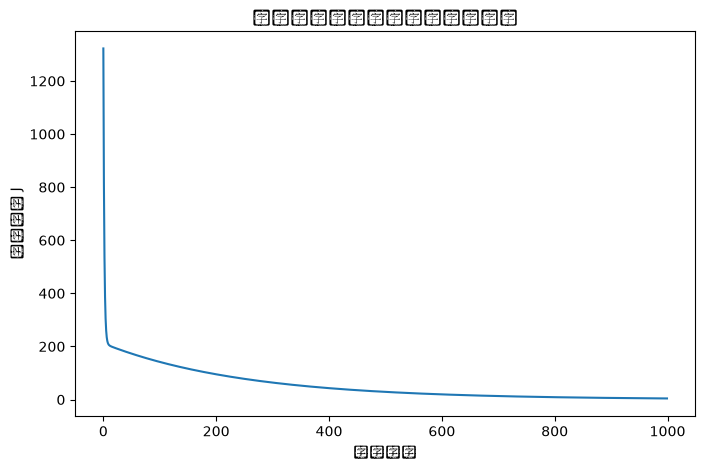

In [5]:
import matplotlib.pyplot as plt

b0 = 0
b1 = 0

n = len(X)
learning_rate = 0.01
epochs = 1000
J_history = []

for i in range(epochs):
    Y_hat = b0 + b1 * X
    b0 = b0 + (learning_rate * np.sum(Y - Y_hat))/n
    b1 = b1 + (learning_rate * np.sum(X * (Y - Y_hat)))/n
    J_history.append(np.sum((Y - b0 - b1 * X)**2)/(2*n))

print(J_history)

plt.figure(figsize=(8,5))
plt.plot(J_history)
plt.xlabel("迭代次数")
plt.ylabel("损失函数 J")
plt.title("梯度下降过程中损失函数的变化")
plt.show


## 8.python新知识

1.迭代epochs = 1000次，即for i in range(1000)循环

2.尽量写短代码，一步一步拆开方便修正和观看，对于需要重复计算的，设置成一个新变量

3.for i in range(1000):是循环1000次的意思，不用 i=i+1

4.X.reshape(样本数, 特征数)，一维转变为二维，因为SGDRegressor 要求 X 是二维的

5.使用 scikit-learn 库，令model = 该模型名称，model.fit(X, Y)即可

6..ipynb文件实现完重新赋值后会存储记忆

7.可视化需要把每一轮的参数和损失函数保存下来

8.生成列表：空列表.append，不能直接给J[i]赋值，因为i位置此时不存在

9.plt.figure(figsize(宽度,高度))，单位：英寸:设置画布。plt.plot( )：画折线图，plt.xlabel("迭代次数"):给横轴加名字，plt.title("梯度下降过程中损失函数的变化")：加标题。plt.show：绘图

10.Y_hat = b0 + b1 * X，为了防止求b1的时候已经用了更新的b0。